<a href="https://colab.research.google.com/github/nithinpalacherla-sys/Inventors/blob/main/CS2740_HW6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 2740 — Homework 6

**Name:**  
**GTID:**  
**Due:** Monday, October 26, 11:59pm (single PDF via Gradescope)

---

### Instructions

Run this notebook in **Google Colab**. Everything it uses is already installed there.

1. Fill in every cell marked `YOUR CODE HERE` and every written answer marked
   *Your answer here*. Double-click a text cell to edit it, and type math between
   dollar signs, for example `$T_2 = 1.753931$`.
2. One part asks for a drawing. Draw the phase portrait in Problem 3 by hand,
   photograph it, and upload the photo when the cell asks for one. Colab deletes
   uploaded files when the runtime disconnects, so you may need to upload it again
   before your final run.
3. Cells marked *provided* run your code and draw the figures. You do not need to
   change them, but you do need to run them.
4. When you are done, run **Runtime → Restart and run all**.
5. Check your output before exporting. No cell output should be cut off, and every
   figure should fit on the page.
6. **File → Print → Save as PDF**, and submit that single PDF to Gradescope.

## Setup

In [2]:
import os

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.integrate import solve_ivp


def show_uploaded_image(filename, width=7):
    """
    Display a picture you have uploaded to Colab.

    If `filename` is not in the session files yet, an upload dialog opens, and
    whatever file you choose is saved under that name.
    """
    if not os.path.exists(filename):
        from google.colab import files
        print(f"{filename} not found. Choose your picture in the upload dialog.")
        uploaded = files.upload()
        os.rename(next(iter(uploaded)), filename)
    img = ImageOps.exif_transpose(Image.open(filename))
    img.thumbnail((1600, 1600))
    plt.figure(figsize=(width, width * img.height / img.width))
    plt.imshow(img)
    plt.axis("off")
    plt.show()


def ratio_table(labels, values, label_name="n"):
    """
    Provided. Print estimates together with the ratio of successive differences.
    A ratio near 2 means first order, near 4 second order, near 16 fourth order.
    """
    print(f"{label_name:>8} {'estimate':>18} {'difference':>14} {'ratio':>10}")
    diffs = [None] + [values[k] - values[k-1] for k in range(1, len(values))]
    for k, (lab, val) in enumerate(zip(labels, values)):
        d = diffs[k]
        if d is None:
            print(f"{lab:>8} {val:>18.12f}")
        elif k + 1 < len(values) and diffs[k+1] not in (None, 0.0):
            print(f"{lab:>8} {val:>18.12f} {d:>14.2e} {abs(d/diffs[k+1]):>10.2f}")
        else:
            print(f"{lab:>8} {val:>18.12f} {d:>14.2e}")

---

# Problem 1 — From a Higher-Order Equation to a System

$$\ddot y + 5\dot y + 6y = 0, \qquad y(0) = 2, \qquad \dot y(0) = -1$$

### (a) The first-order system

Introduce one variable for $y$ and one for $\dot y$, write the two differential equations, and state the initial condition for each variable.

Let $x_1 = y$ and $x_2 = \dot y$.

Then $\dot x_1 = x_2$ and $\dot x_2 = -6x_1 -5x_2$ with initial conditions $x_1(0) = y(0) = 2$ and $x_2(0) = \dot y(0) = -1$.



### (b) Matrix form

Write the same system as $\dot{\mathbf{x}} = A\mathbf{x}$, giving the state vector $\mathbf{x}$ and the matrix $A$.

Define the state vector:

  $ x = \begin{pmatrix} x_1 \\ x_2 \end{pmatrix}$


Then the system can be written as $\dot{\mathbf{x}} = A\mathbf{x}$, where

  $A = \begin{pmatrix} 0 & 1 \\ -6 & -5 \end{pmatrix},
  \qquad
  \mathbf{x}(0) = \begin{pmatrix} 2 \\ -1 \end{pmatrix}.$


---

# Problem 2 — Solving Differential Equations Numerically

### (a) One RK4 step by hand

For $\dot y = -2y$ with $y(0) = 1$ and $h = 0.1$, report $k_1$, $k_2$, $k_3$, $k_4$, and $y_1$, and compare $y_1$ with $e^{-0.2}$.

$k_1 = f(y_0) = -2(1) = -2$

$k_2 = f\left(y_0 + \tfrac{h}{2}k_1\right) = -2\left(1 + 0.05(-2)\right) = -2(0.9) = -1.8$

$k_3 = f\left(y_0 + \tfrac{h}{2}k_2\right) = -2\left(1 + 0.05(-1.8)\right) = -2(0.91) = -1.82$

$k_4 = f\left(y_0 + h\,k_3\right) = -2\left(1 + 0.1(-1.82)\right) = -2(0.818) = -1.636$

$y_1 = y_0 + \frac{h}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right) = 1 + \frac{0.1}{6}(-10.876) \approx 0.8187333$

$e^{-0.2} \approx 0.8187308,\qquad |y_1 - e^{-0.2}| \approx 2.6\times10^{-6}$

### (b) Forward Euler

Write `euler_solve(f, t0, y0, h, T)`. It should return two arrays, the times visited and the solution at each of them. Build the times with `np.arange(t0, T + h, h)` and write the update with array arithmetic so the same function works when `y0` is an array.

In [3]:
def euler_solve(f, t0, y0, h, T):
    """
    TODO. Step from t0 to T with forward Euler and return (ts, ys), where
    ys[k] is the solution at ts[k].
    """
    # YOUR CODE HERE
    n = int(round((T - t0) / h))
    ts = t0 + h * np.arange(n + 1)
    ys = np.zeros((n + 1,) + np.shape(y0))
    ys[0] = y0
    for k in range(n):
        ys[k + 1] = ys[k] + h * f(ts[k], ys[k])
    return ts, ys


# Provided. A short run on dy/dt = -2y, whose exact solution is exp(-2t).
ts, ys = euler_solve(lambda t, y: -2*y, 0.0, 1.0, 0.1, 1.0)
if ts is not None:
    print("last time reached", ts[-1], "with", len(ts), "points")
    print("y at T = 1 is", ys[-1], "against the exact", np.exp(-2))

last time reached 1.0 with 11 points
y at T = 1 is 0.10737418240000003 against the exact 0.1353352832366127


### (c) RK4

Write `rk4_solve(f, t0, y0, h, T)` with the same inputs and outputs.

In [5]:
def rk4_solve(f, t0, y0, h, T):
    """
    TODO. Step from t0 to T with RK4 and return (ts, ys).
    """
    # YOUR CODE HERE
    n = int(round((T - t0) / h))
    ts = t0 + h * np.arange(n + 1)
    ys = np.zeros((n + 1,) + np.shape(y0))
    ys[0] = y0
    for k in range(n):
        t, y = ts[k], ys[k]
        k1 = f(t, y)
        k2 = f(t + h/2, y + h/2 * k1)
        k3 = f(t + h/2, y + h/2 * k2)
        k4 = f(t + h, y + h * k3)
        ys[k + 1] = y + h/6 * (k1 + 2*k2 + 2*k3 + k4)
    return ts, ys


# Provided.
ts, ys = rk4_solve(lambda t, y: -2*y, 0.0, 1.0, 0.1, 1.0)
if ts is not None:
    print("y at T = 1 is", ys[-1], "against the exact", np.exp(-2))

y at T = 1 is 0.13533954843051013 against the exact 0.1353352832366127


### (d) Order of the two methods

Run the provided cell, then report the ratio each method settles to and the order each one indicates. One RK4 step has error of size $h^5$, so explain why the order you measured for RK4 is not 5.

The Euler ratio settles to 2, so Euler is first order. The RK4 ratio settles to 16 = $2^4$, so RK4 is fourth order.

RK4 measures 4, not 5, because $h^5$ is the error from a single step. Reaching T takes T/h steps, and those errors add up to about (T/h)·$h^5$ = $h^4$. Halving h makes each step’s error 32 times smaller but doubles the number of steps, so the total error shrinks by 32/2 = 16.

In [6]:
# Provided.
hs = [0.1 / 2**k for k in range(7)]


def final_value(solver, h):
    ts, ys = solver(lambda t, y: -2*y, 0.0, 1.0, h, 1.0)
    return float(np.ravel(ys[-1])[0])


if euler_solve(lambda t, y: -2*y, 0.0, 1.0, 0.1, 1.0)[0] is None or \
   rk4_solve(lambda t, y: -2*y, 0.0, 1.0, 0.1, 1.0)[0] is None:
    print("Write euler_solve and rk4_solve first, then run this cell.")
else:
    print("Forward Euler")
    ratio_table([f"{h:g}" for h in hs], [final_value(euler_solve, h) for h in hs], "h")
    print("\nRK4")
    ratio_table([f"{h:g}" for h in hs], [final_value(rk4_solve, h) for h in hs], "h")

Forward Euler
       h           estimate     difference      ratio
     0.1     0.107374182400
    0.05     0.121576654591       1.42e-02       2.05
   0.025     0.128512156565       6.94e-03       2.02
  0.0125     0.131937805387       3.43e-03       2.01
 0.00625     0.133640067942       1.70e-03       2.01
0.003125     0.134488556634       8.48e-04       2.00
0.0015625     0.134912140205       4.24e-04

RK4
       h           estimate     difference      ratio
     0.1     0.135339548431
    0.05     0.135335528422      -4.02e-06      17.44
   0.025     0.135335297934      -2.30e-07      16.70
  0.0125     0.135335284136      -1.38e-08      16.35
 0.00625     0.135335283292      -8.44e-10      16.17
0.003125     0.135335283240      -5.22e-11      16.09
0.0015625     0.135335283237      -3.24e-12


### (e) A step size Euler cannot take

Run the provided cell, then describe what the three solutions do. Using the fact that Euler applied to $\dot y = -\lambda y$ multiplies the solution by $1 - h\lambda$ at every step, explain the three behaviors and find the largest step size for which Euler decays on this equation.

Each Euler step multiplies $y$ by $1 - 2h$. For $h = 0.9$ the factor is $-0.8$, so the solution alternates in sign and decays. For $h = 1.0$ it is $-1$, so the solution oscillates between $\pm 1$ forever. For $h = 1.1$ it is $-1.2$, so the solution alternates and grows without bound. Euler decays only when $|1 - 2h| < 1$, i.e.\ $0 < h < 1$, so the step size must stay below $h = 2/\lambda = 1$.

h = 0.9: first six values [ 1.     -0.8     0.64   -0.512   0.4096 -0.3277]
h = 1.0: first six values [ 1. -1.  1. -1.  1. -1.]
h = 1.1: first six values [ 1.     -1.2     1.44   -1.728   2.0736 -2.4883]


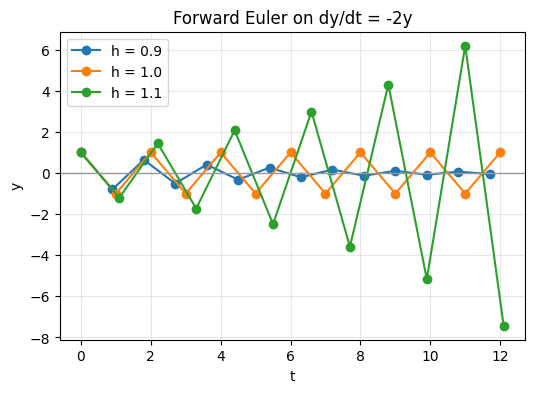

In [7]:
# Provided.
if euler_solve(lambda t, y: -2*y, 0.0, 1.0, 0.9, 1.0)[0] is None:
    print("Write euler_solve first, then run this cell.")
else:
    plt.figure(figsize=(6, 4))
    for h in (0.9, 1.0, 1.1):
        ts, ys = euler_solve(lambda t, y: -2*y, 0.0, 1.0, h, 12.0)
        ys = np.ravel(ys)
        print(f"h = {h}: first six values {np.round(ys[:6], 4)}")
        plt.plot(ts, ys, "o-", label=f"h = {h}")
    plt.axhline(0, color="0.6", lw=1)
    plt.xlabel("t")
    plt.ylabel("y")
    plt.title("Forward Euler on dy/dt = -2y")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

### (f) A nonlinear system

A prey population $u$ and a predator population $v$ obey

$$\dot u = u(1 - v), \qquad \dot v = -\alpha v(1 - u), \qquad \alpha = 1.$$

Write this vector field in the cell below, in the form your solvers expect, then run it. It solves the system from $u(0) = 1.5$, $v(0) = 1$ out to $T = 50$ with $h = 0.05$ using both methods, plots both trajectories in the $uv$ plane, and reports the largest change in

$$V = \alpha(u - \ln u) + (v - \ln v),$$

a quantity that stays constant along exact solutions of this system.

Describe how the two trajectories differ, report the two values, and say which trajectory is an artifact of the method rather than a property of the model.

The RK4 trajectory is a single closed orbit around the equilibrium $(1,1)$, with $u$ and $v$ cycling between about $0.63$ and $1.5$. The Euler trajectory spirals outward each cycle, reaching $u \approx 3.0$ and $v \approx 3.1$ by $T = 50$. The largest change in $V$ is $1.009$ for Euler and $2.675 \times 10^{-8}$ for RK4. Since $V$ is conserved along exact solutions, the true orbits are closed, so the outward spiral is an artifact of forward Euler, while the closed RK4 orbit reflects the model itself.

 Euler: largest change in V is 1.009e+00
   RK4: largest change in V is 2.675e-08


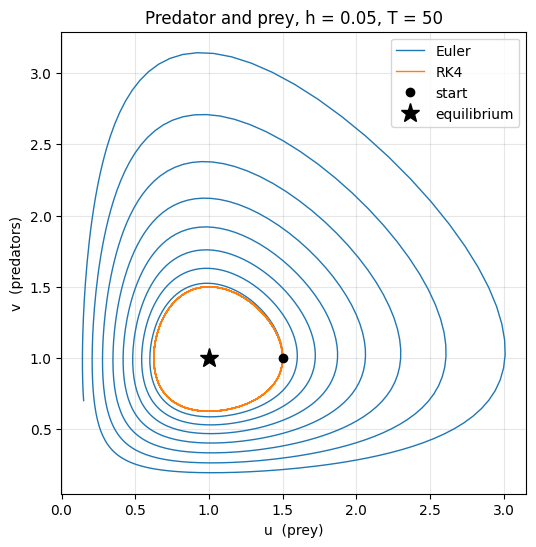

In [8]:
ALPHA_PP = 1.0   # alpha for this problem


def predator_prey(t, z):
    """
    TODO. Return the vector field [du/dt, dv/dt] at the state z = [u, v],
    using ALPHA_PP for alpha. Return a numpy array.
    """
    # YOUR CODE HERE
    u, v = z
    return np.array([u * (1 - v), -ALPHA_PP * v * (1 - u)])


# Provided. Solves from (1.5, 1) with both methods and measures the drift in V.
def V(z):
    z = np.asarray(z, dtype=float)
    return ALPHA_PP * (z[0] - np.log(z[0])) + (z[1] - np.log(z[1]))


z0, h, T = np.array([1.5, 1.0]), 0.05, 50.0

if predator_prey(0.0, z0) is None or euler_solve(predator_prey, 0.0, z0, 0.1, 0.2)[0] is None:
    print("Write predator_prey, euler_solve and rk4_solve first, then run this cell.")
else:
    runs = {}
    for name, solver in [("Euler", euler_solve), ("RK4", rk4_solve)]:
        ts, zs = solver(predator_prey, 0.0, z0, h, T)
        runs[name] = (ts, np.asarray(zs))
        drift = max(abs(V(z) - V(z0)) for z in np.asarray(zs))
        print(f"{name:>6}: largest change in V is {drift:.3e}")

    plt.figure(figsize=(6, 6))
    for name, (ts, zs) in runs.items():
        plt.plot(zs[:, 0], zs[:, 1], lw=1, label=name)
    plt.plot(*z0, "ko", label="start")
    plt.plot(1, 1, "k*", ms=14, label="equilibrium")
    plt.xlabel("u  (prey)")
    plt.ylabel("v  (predators)")
    plt.title("Predator and prey, h = 0.05, T = 50")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

---

# Problem 3 — A Chemostat

$$\frac{ds}{d\tau} = \alpha(\beta - s) - \frac{su}{1 + s}, \qquad \frac{du}{d\tau} = u\left(\frac{s}{1 + s} - \alpha\right)$$

with $\alpha = 0.3$ and $\beta = 2$.

### (a) Nullclines and equilibria

Give both nullclines, including both branches of the $u$-nullcline, and both equilibria.

The $s$-nullcline is $\alpha(\beta - s) = \frac{su}{1+s}$, $u = \frac{\alpha(\beta - s)(1+s)}{s} = \frac{0.3(2-s)(1+s)}{s}$. The $u$-nullcline is $u\left(\frac{s}{1+s} - \alpha\right) = 0$, which has two branches: $u = 0$ and $s = \frac{\alpha}{1-\alpha} = \frac{3}{7}$. The equilibria are the washout state $(s,u) = (2, 0)$ and the coexistence state $(s,u) = \left(\frac{3}{7}, \frac{11}{7}\right) \approx (0.429, 1.571)$.

### (b) Jacobian and classification

Give the Jacobian at a general point $(s, u)$, then evaluate it at each equilibrium and report $\tau = \operatorname{tr} J$, $\Delta = \det J$, the eigenvalues, and the classification.

$J(s,u) = \begin{pmatrix} -\alpha - \frac{u}{(1+s)^2} & -\frac{s}{1+s} \\[2pt] \frac{u}{(1+s)^2} & \frac{s}{1+s} - \alpha \end{pmatrix}$.
At $(2,0)$: $\tau = \frac{1}{15}$, $\Delta = -0.11$, $\lambda = -0.3,\ \frac{11}{30}$, so it is a saddle.
At $\left(\frac{3}{7}, \frac{11}{7}\right)$: $\tau = -1.07$, $\Delta = 0.231$, $\lambda = -0.3,\ -0.77$, so it is a stable node.

### (c) Phase portrait by hand

Make a rough sketch of the phase portrait, marking the nullclines, both equilibria, the flow direction in each region, and several trajectories. It does not need to be to scale. Photograph it and run the cell below.

phase_sketch not found. Choose your picture in the upload dialog.


Saving Screenshot 2026-10-23 at 2.28.04 PM.png to Screenshot 2026-10-23 at 2.28.04 PM.png


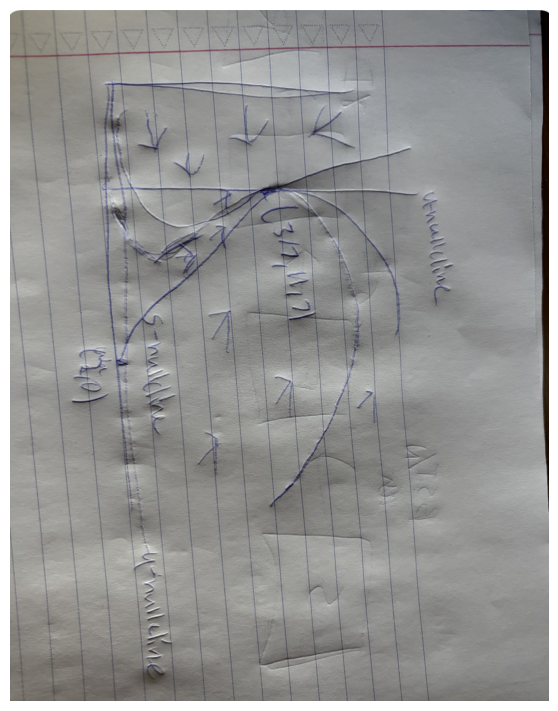

In [17]:
show_uploaded_image("phase_sketch")

### (d) `jacobian` and `classify`

Write both functions in the cell below. Vector fields are written in the form `f(t, x)`, so `f(0.0, x)` returns the field at the point `x`.

`classify` returns five things. These are the Jacobian, $\tau$, $\Delta$, the eigenvalues, and the classification as one of the strings `"saddle"`, `"stable node"`, `"unstable node"`, `"stable spiral"`, `"unstable spiral"`, `"center"`. Do not hard-code the chemostat.

Useful functions are `np.eye(n)[j]`, which is the $j$-th unit vector, and `np.linalg.eigvals(J)`, which returns the eigenvalues. A complex eigenvalue `z` has `z.real` and `z.imag`.

In [10]:
def jacobian(f, x, eps=1e-6):
    """
    TODO. Estimate the Jacobian at x of the vector field f, which is
    written in the form f(t, x), by finite differences,
    J[i][j] = (f_i(x + eps * e_j) - f_i(x)) / eps.
    Return an n x n array.
    """
    # YOUR CODE HERE
    x = np.asarray(x, dtype=float)
    fx = np.asarray(f(0.0, x), dtype=float)
    n = len(x)
    J = np.zeros((n, n))
    for j in range(n):
        e = np.zeros(n)
        e[j] = 1.0
        J[:, j] = (np.asarray(f(0.0, x + eps * e)) - fx) / eps
    return J



def classify(f, x):
    """
    TODO. Return (J, tau, Delta, eigenvalues, name), where J is the Jacobian at
    x, tau is its trace, Delta its determinant, and name is one of
    "saddle", "stable node", "unstable node", "stable spiral",
    "unstable spiral", "center".
    """
    # YOUR CODE HERE
    tol = 1e-4
    J = jacobian(f, x)
    tau = np.trace(J)
    Delta = np.linalg.det(J)
    eigenvalues = np.linalg.eigvals(J)
    if Delta < 0:
        name = "saddle"
    elif abs(tau) < tol:
        name = "center"
    elif tau**2 - 4*Delta >= 0:
        name = "stable node" if tau < 0 else "unstable node"
    else:
        name = "stable spiral" if tau < 0 else "unstable spiral"
    return J, tau, Delta, eigenvalues, name


# Provided. Two test systems whose classification you can check by hand.
def test_saddle(t, x):
    return np.array([x[0], -x[1]])           # eigenvalues +1 and -1


def test_spiral(t, x):
    return np.array([-x[0] - 2*x[1], 2*x[0] - x[1]])   # eigenvalues -1 +/- 2i


for name, g in [("test_saddle", test_saddle), ("test_spiral", test_spiral)]:
    result = classify(g, np.array([0.0, 0.0]))
    print(f"{name}: {result if result is None else result[4]}")
print('expected --- test_saddle gives "saddle", test_spiral gives "stable spiral"')

test_saddle: saddle
test_spiral: stable spiral
expected --- test_saddle gives "saddle", test_spiral gives "stable spiral"


### (e) Classify both equilibria

Enter the two equilibria you found in part (a) and run the cell. Compare the classifications with your answers to part (b). Report any disagreement and say which you trust.

Both agree to part(b), so there is no disagreement. If there was a disagreement, I would have trusted the hand calculation.

In [12]:
ALPHA, BETA = 0.3, 2.0


def chemostat(t, x, alpha=ALPHA, beta=BETA):
    """Provided. The chemostat vector field, written in the form f(t, x)."""
    s, u = x
    return np.array([alpha*(beta - s) - s*u/(1 + s), u*(s/(1 + s) - alpha)])


# Enter your two equilibria from part (a), as [s, u] for each.
# YOUR CODE HERE
WASHOUT = [2.0, 0.0]
SURVIVAL = [3/7, 11/7]

# Provided. Classifies each of the points you entered.
if None in WASHOUT or None in SURVIVAL:
    print("Fill in WASHOUT and SURVIVAL with the equilibria from part (a).")
else:
    for label, point in [("washout", WASHOUT), ("survival", SURVIVAL)]:
        J, tau, Delta, eigs, name = classify(chemostat, np.array(point, dtype=float))
        print(f"{label:>9} at {np.round(point, 4)}: tau = {tau:.4f}, Delta = {Delta:.4f}, "
              f"eigenvalues = {np.round(eigs, 4)}, {name}")

  washout at [2. 0.]: tau = 0.0667, Delta = -0.1100, eigenvalues = [-0.3     0.3667], saddle
 survival at [0.4286 1.5714]: tau = -1.0700, Delta = 0.2310, eigenvalues = [-0.77 -0.3 ], stable node


### (f) Phase planes and the sweep

Run the three provided cells below, which draw the phase plane at $\alpha = 0.3$, the phase plane at $\alpha = 0.8$, and the sweep of $\alpha$ from $0.1$ to $0.9$. Then describe how the two phase planes differ and report where the classification of the washout state changes.

At $\alpha = 0.3$, trajectories converge to the survival state $\left(\frac{3}{7}, \frac{11}{7}\right)$ and washout is a saddle. At $\alpha = 0.8$, the survival state has $u < 0$, so every trajectory goes to washout, which is a stable node. Washout's eigenvalues are $-\alpha$ and $\frac{2}{3} - \alpha$, so it changes from a saddle to a stable node at $\alpha = \frac{2}{3}$.

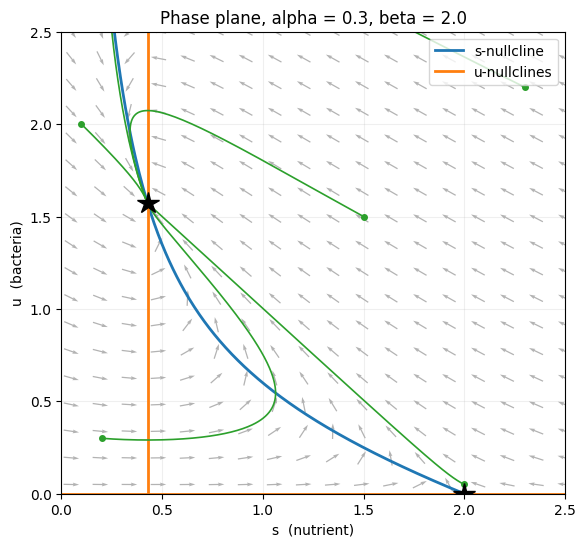

In [14]:
# Provided. Draws the phase plane for a given alpha.

def phase_plane(alpha, beta=2.0, title=None):
    f = lambda t, x: chemostat(t, x, alpha, beta)
    smax = umax = 2.5

    fig, ax = plt.subplots(figsize=(6.5, 6))

    # direction field
    S, U = np.meshgrid(np.linspace(0.05, smax, 18), np.linspace(0.05, umax, 18))
    dS, dU = np.zeros_like(S), np.zeros_like(U)
    for i in range(S.shape[0]):
        for j in range(S.shape[1]):
            dS[i, j], dU[i, j] = f(0.0, np.array([S[i, j], U[i, j]]))
    norm = np.hypot(dS, dU)
    ax.quiver(S, U, dS/norm, dU/norm, color="0.7", pivot="mid", width=0.0025)

    # nullclines
    s_grid = np.linspace(0.02, smax, 400)
    ax.plot(s_grid, alpha*(beta - s_grid)*(1 + s_grid)/s_grid, color="tab:blue",
            lw=2, label="s-nullcline")
    ax.axhline(0, color="tab:orange", lw=2, label="u-nullclines")
    s_branch = alpha/(1 - alpha) if alpha < 1 else np.inf
    if 0 < s_branch < smax:
        ax.axvline(s_branch, color="tab:orange", lw=2)

    # trajectories
    for x0 in [(2.0, 0.05), (0.1, 2.0), (1.5, 1.5), (0.2, 0.3), (2.3, 2.2)]:
        sol = solve_ivp(f, (0, 80), x0, dense_output=True,
                        rtol=1e-8, atol=1e-10)
        t = np.linspace(0, 80, 2000)
        y = sol.sol(t)
        ax.plot(y[0], y[1], color="tab:green", lw=1.2)
        ax.plot(*x0, "o", color="tab:green", ms=4)

    # equilibria
    ax.plot(beta, 0, "k*", ms=16, zorder=5)
    if 0 < s_branch < beta:
        ax.plot(s_branch, beta - s_branch, "k*", ms=16, zorder=5)

    ax.set_xlim(0, smax)
    ax.set_ylim(0, umax)
    ax.set_xlabel("s  (nutrient)")
    ax.set_ylabel("u  (bacteria)")
    ax.set_title(title or f"Phase plane, alpha = {alpha}, beta = {beta}")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)
    plt.show()


phase_plane(0.3)

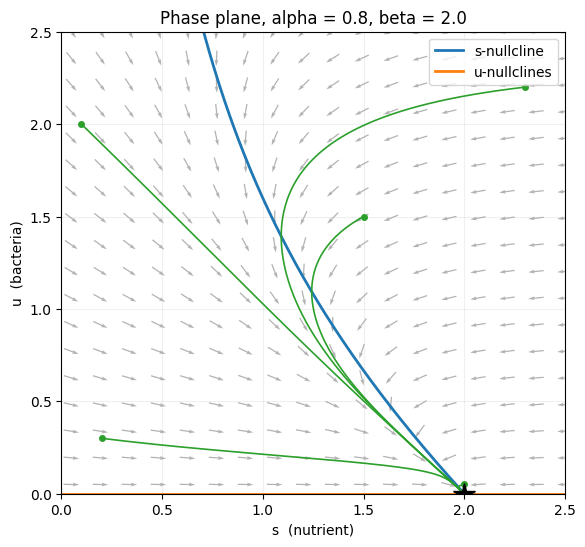

In [15]:
# Provided.
phase_plane(0.8)

In [16]:
# Provided. Classifies the washout state as alpha sweeps from 0.1 to 0.9.
alphas = np.round(np.arange(0.1, 0.9001, 0.02), 2)

if classify(lambda t, x: chemostat(t, x, 0.3, 2.0), np.array([2.0, 0.0])) is None:
    print("Write classify in part (d) first, then run this cell.")
else:
    labels = [classify(lambda t, x: chemostat(t, x, a, 2.0), np.array([2.0, 0.0]))[4] for a in alphas]
    start = 0
    for k in range(1, len(alphas) + 1):
        if k == len(alphas) or labels[k] != labels[start]:
            print(f"alpha {alphas[start]:.2f} to {alphas[k-1]:.2f}: {labels[start]}")
            start = k

alpha 0.10 to 0.66: saddle
alpha 0.68 to 0.90: stable node
